In [1]:
# Completa: define tu diccionario de lugares con coordenadas reales
lugares = {
    "UNSAAC (Perayoc)": (-13.5229, -71.9585),
    "Real Plaza Cusco": (-13.5262, -71.9468),
    "Plaza San Sebastián": (-13.5326, -71.9332),
    "Pasaje Breña (San Sebastián)": (-13.5342, -71.9310),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

UNSAAC (Perayoc): lat=-13.5229, lon=-71.9585
Real Plaza Cusco: lat=-13.5262, lon=-71.9468
Plaza San Sebastián: lat=-13.5326, lon=-71.9332
Pasaje Breña (San Sebastián): lat=-13.5342, lon=-71.931


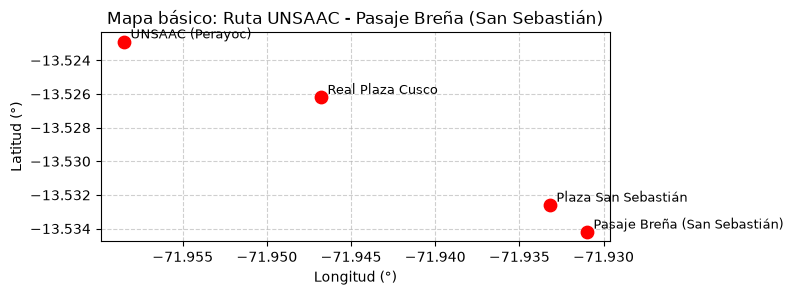

In [2]:
import matplotlib.pyplot as plt

# Completa: extrae lats y lons, y grafica
nombres = list(lugares.keys())
lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(lons, lats, color="red", s=80, zorder=5)

# Etiquetas de texto para cada lugar
for nombre, (lat, lon) in lugares.items():
    ax.text(lon + 0.0004, lat + 0.0002, nombre, fontsize=9)

ax.set_title("Mapa básico: Ruta UNSAAC - Pasaje Breña (San Sebastián)")
ax.set_xlabel("Longitud (°)")
ax.set_ylabel("Latitud (°)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("mapa_basico.png", dpi=300)
plt.show()

In [9]:
import math


# Completa: define la funcion distancia_haversine
def distancia_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Radio de la Tierra en km
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = (
        math.sin(dphi / 2) ** 2
        + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    )
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

In [5]:
# Completa: calcula las distancias desde tu primer lugar
primer_nombre = list(lugares.keys())[0]
lat1, lon1 = lugares[primer_nombre]

print(f"Distancias desde {primer_nombre}:")
for nombre, (lat2, lon2) in lugares.items():
    if nombre != primer_nombre:
        d = distancia_haversine(lat1, lon1, lat2, lon2)
        print(f"  -> Hacia {nombre}: {d:.3f} km")

Distancias desde UNSAAC (Perayoc):
  -> Hacia Real Plaza Cusco: 1.317 km
  -> Hacia Plaza San Sebastián: 2.940 km
  -> Hacia Pasaje Breña (San Sebastián): 3.228 km


In [6]:
# Completa: identifica el par mas cercano y el mas lejano
nombres = list(lugares.keys())
pares = []

for i in range(len(nombres)):
    for j in range(i + 1, len(nombres)):
        n1, n2 = nombres[i], nombres[j]
        lat1, lon1 = lugares[n1]
        lat2, lon2 = lugares[n2]
        dist = distancia_haversine(lat1, lon1, lat2, lon2)
        pares.append((dist, n1, n2))

mas_cercano = min(pares)
mas_lejano = max(pares)

print(
    f"Par MÁS CERCANO: {mas_cercano[1]} y {mas_cercano[2]} ({mas_cercano[0]:.3f} km)"
)
print(
    f"Par MÁS LEJANO:  {mas_lejano[1]} y {mas_lejano[2]} ({mas_lejano[0]:.3f} km)"
)

Par MÁS CERCANO: Plaza San Sebastián y Pasaje Breña (San Sebastián) (0.297 km)
Par MÁS LEJANO:  UNSAAC (Perayoc) y Pasaje Breña (San Sebastián) (3.228 km)


In [7]:
import json

# Completa: construye la lista de features y el GeoJSON completo
features = []

for nombre, (lat, lon) in lugares.items():
    feature = {
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat],  # Orden estricto: [longitud, latitud]
        },
    }
    features.append(feature)

geojson_mio = {"type": "FeatureCollection", "features": features}

# Completa: guarda el archivo
with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, indent=2, ensure_ascii=False)

In [8]:
# Completa: reabre y verifica
with open("mis_lugares.geojson", "r", encoding="utf-8") as f:
    datos_verificados = json.load(f)

num_features = len(datos_verificados["features"])
primer_feature = datos_verificados["features"][0]
nombre_primero = primer_feature["properties"]["nombre"]
coords_primero = primer_feature["geometry"]["coordinates"]

print(f"Número total de features: {num_features} (esperado: {len(lugares)})")
print(f"Primer lugar: {nombre_primero}")
print(
    f"Coordenadas guardadas [lon, lat]: {coords_primero} (esperado: [{lugares[nombre_primero][1]}, {lugares[nombre_primero][0]}])"
)

Número total de features: 4 (esperado: 4)
Primer lugar: UNSAAC (Perayoc)
Coordenadas guardadas [lon, lat]: [-71.9585, -13.5229] (esperado: [-71.9585, -13.5229])


SyntaxError: invalid syntax (3528599804.py, line 1)